In [1]:
import spacy
from spacy.cli import download
import pandas as pd 
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
# Cargar modelo en español
try:
    nlp = spacy.load("es_core_news_sm")
except OSError:
    print("Descargando modelo...")
    download("es_core_news_sm")
    nlp = spacy.load("es_core_news_sm")

# Texto de entrada:
with open ("./pinochoCap1.txt", "r", encoding="utf-8") as f:
    texto_pinocho = f.read()

# Longitud del texto del archivo
print(f"Texto cargado con exito. Longitud: {len(texto_pinocho)} caracteres")

# 1. TOKENIZACIÓN
# SpaCy procesa el texto y crea el objeto 'doc'
doc = nlp(texto_pinocho)

# Mostrar los primeros 15 tokens
print(f"--- 1. Tokenización (Total tokens: {len(doc)} ---)")
print([token.text for token in doc][:20])

Texto cargado con exito. Longitud: 4454 caracteres
--- 1. Tokenización (Total tokens: 1045 ---)
['Escuchen', ',', 'mis', 'pequeños', 'lectores', '.', '\n', 'Había', 'una', 'vez', 'un', 'pedazo', 'de', 'madera', '.', 'Un', 'simple', 'trozo', '\n', 'de']


In [5]:
# 2 FILTRADO DE STOP WORDS

tokens_relevantes = []
tokens_ruido =[]

for token in doc:
    if not token.is_stop and not token.is_punct and token.text.strip():
        tokens_relevantes.append(token.text)
    elif token.is_stop:
        tokens_ruido.append(token.text)

print(f"\n --- Filtrado de Stop Words ---")
print(f"Palabras eliminadas (ruido): {tokens_ruido[:10]}...")
print(f"Palabras conservadas (contenido): {tokens_relevantes[:10]}")
print(f"Reducción de tamaño de {len(doc)} a {len(tokens_relevantes)} tokens.")


 --- Filtrado de Stop Words ---
Palabras eliminadas (ruido): ['mis', 'Había', 'una', 'vez', 'un', 'de', 'Un', 'de', 'de', 'esos']...
Palabras conservadas (contenido): ['Escuchen', 'pequeños', 'lectores', 'pedazo', 'madera', 'simple', 'trozo', 'leña', 'invierno', 'encienden']
Reducción de tamaño de 1045 a 336 tokens.


In [10]:
# 3. LEMATIZACIÓN Y NORMALIZACIÓN
# Reducir las palabras a su raíz (lematizaciión) y estandarizar minúsculas
# Objetivo: Que "hablo" "hablare" y "habla" -> "hablar"

tokens_normalizados = []

for token in doc:
    if not token.is_stop and not token.is_punct and token.text.strip():

        lema = token.lemma_.lower()
        tokens_normalizados.append(lema)

print(f"\n--- 3. Normalización y Lematización ---")
print(f"Total de tokens procesados: {len(tokens_normalizados)}")
print(f"\nResultado final (Primeros 10 tokens):")
print(tokens_normalizados[:20])



--- 3. Normalización y Lematización ---
Total de tokens procesados: 336

Resultado final (Primeros 10 tokens):
['escuchen', 'pequeño', 'lector', 'pedazo', 'madera', 'simple', 'trozo', 'leña', 'invierno', 'encender', 'estufa', 'chimenea', 'calentar', 'habitación', 'niño', 'caso', 'trozo', 'leña', 'cuento', 'parar']


In [14]:
# 4. VECTORIZACIÓN

corpus_lematizado = []
for oracion in doc.sents:
    lemas_oracion = [
        token.lemma_.lower()
        for token in oracion
        if not token.is_punct and not token.is_space and not token.is_stop
    ]
    if lemas_oracion:
        corpus_lematizado.append(" ".join(lemas_oracion))

print(f"Total de oraciones procesadas: {len(corpus_lematizado)}")
print(f"\nPrimeras 3 oraciones: \n{corpus_lematizado[:3]}")

Total de oraciones procesadas: 45

Primeras 3 oraciones: 
['escuchen pequeño lector', 'pedazo madera', 'simple trozo leña invierno encender estufa chimenea calentar habitación']


In [15]:
# Para TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)

In [16]:
# Para Bag of Words
bow_vetorizer = CountVectorizer()
X_bow = bow_vetorizer.fit_transform(corpus_lematizado)

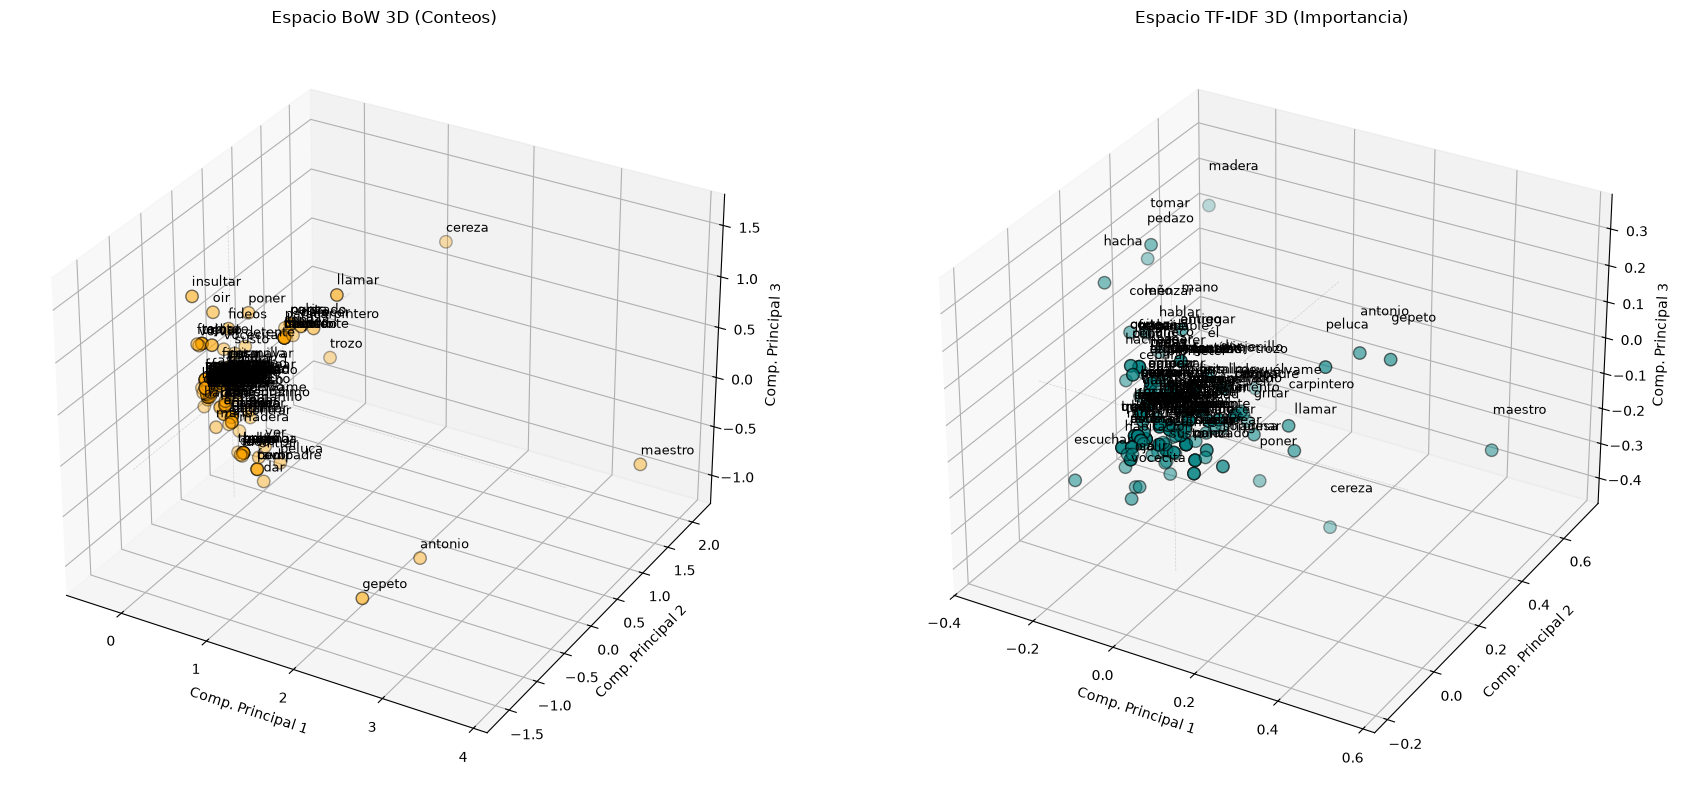

In [18]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # Import necesario para 3D
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np

# ---------------------------------------------------------
# FUNCIÓN AUXILIAR PARA GRAFICAR EN 3D
# ---------------------------------------------------------
def graficar_palabras_3d(ax, matriz, vocabulario, titulo, color_puntos):
    # 1. TRANSPONER: Filas = Palabras, Columnas = Contextos
    matriz_palabras = matriz.T

    # 2. PCA: Reducir a 3 DIMENSIONES
    pca = PCA(n_components=3)
    coords = pca.fit_transform(matriz_palabras.toarray())

    # Extraer coordenadas X, Y, Z
    x = coords[:, 0]
    y = coords[:, 1]
    z = coords[:, 2]

    # 3. GRAFICAR SCATTER 3D
    # Usamos profundidad visual (depthshade=True) para ayudar a la perspectiva
    ax.scatter(x, y, z, c=color_puntos, s=80, edgecolors='k', alpha=0.8, depthshade=True)

    # Etiquetar puntos
    for i, palabra in enumerate(vocabulario):
        # Agregamos un pequeño offset a Z para que el texto flote sobre el punto
        ax.text(x[i], y[i], z[i] + 0.1, palabra, fontsize=9)

    ax.set_title(titulo)
    ax.set_xlabel('Comp. Principal 1')
    ax.set_ylabel('Comp. Principal 2')
    ax.set_zlabel('Comp. Principal 3')

    # Líneas de referencia en el origen (0,0,0)
    ax.plot([0,0], [0,0], [z.min(), z.max()], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([x.min(), x.max()], [0,0], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([0,0], [y.min(), y.max()], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)


# ---------------------------------------------------------
# CONFIGURACIÓN DE LA FIGURA 3D
# ---------------------------------------------------------
# Creamos una figura ancha para poner dos gráficos lado a lado
fig = plt.figure(figsize=(18, 8))

# --- A. BAG OF WORDS (Izquierda) ---
# subplot(filas, columnas, índice, proyección)
ax1 = fig.add_subplot(121, projection='3d')

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(corpus_lematizado)
vocab_bow = bow_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax1, X_bow, vocab_bow,
                     "Espacio BoW 3D (Conteos)",
                     "orange")

# --- B. TF-IDF (Derecha) ---
ax2 = fig.add_subplot(122, projection='3d')

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)
vocab_tfidf = tfidf_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax2, X_tfidf, vocab_tfidf,
                     "Espacio TF-IDF 3D (Importancia)",
                     "teal")

plt.tight_layout()
plt.show()

Procesando texto con SpaCy...
Total de oraciones procesadas: 43
Ejemplo (tokens): ['escuchen', 'pequeño', 'lector']

Entrenando red neuronal Word2Vec...

Palabras más cercanas semánticamente a 'madera':
  - azul (Similitud: 0.6900)
  - salto (Similitud: 0.6758)
  - furioso (Similitud: 0.6479)

Palabras más cercanas semánticamente a 'carpintero':
  - recorrer (Similitud: 0.8244)
  - furioso (Similitud: 0.7056)
  - canturrear (Similitud: 0.6779)


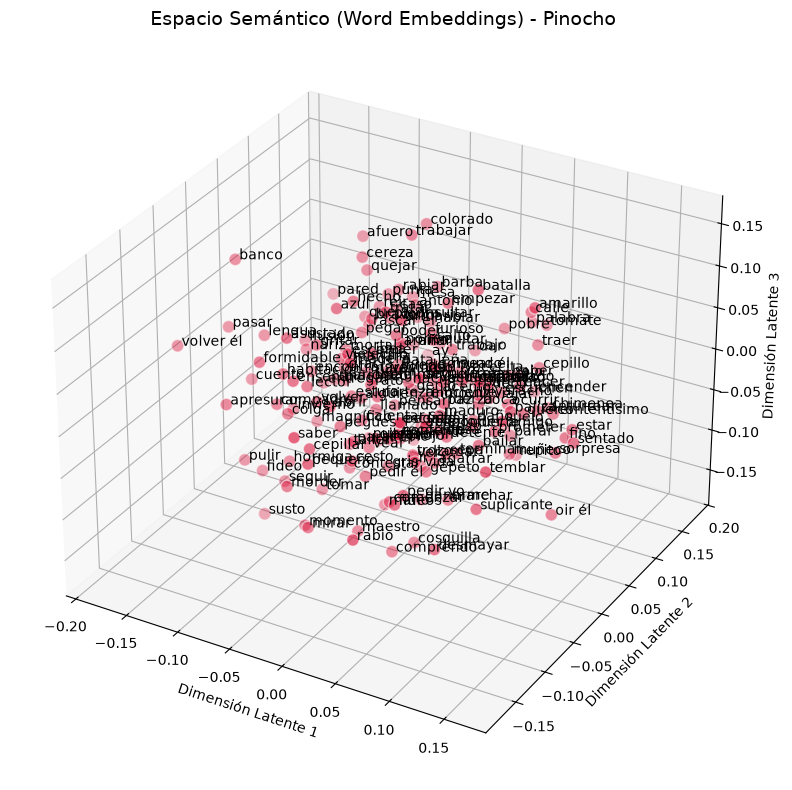


Así ve la máquina la palabra 'madera' (Vector de 10 dimensiones):
[ 0.00019005 -0.02574183 -0.06352728  0.08548076  0.05640603  0.02877706
 -0.01954075  0.06443691  0.00892661 -0.01128239]


In [ ]:
import pandas as pd
import spacy
from gensim.models import Word2Vec
import multiprocessing
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import numpy as np


# 1. PREPARACIÓN DE DATOS
nlp = spacy.load("es_core_news_sm")

with open("./pinochoCap1.txt", "r", encoding="utf-8") as f:
     texto_pinocho = f.read()


print("Procesando texto con SpaCy...")
doc = nlp(texto_pinocho)

sentences = []
for sent in doc.sents:
    # Lematizamos y quitamos stop words para reducir ruido
    tokens = [
        token.lemma_.lower()
        for token in sent
        if not token.is_stop and not token.is_punct and token.text.strip()
    ]
    if len(tokens) > 1: # Solo oraciones con algo de contenido
        sentences.append(tokens)

print(f"Total de oraciones procesadas: {len(sentences)}")
print(f"Ejemplo (tokens): {sentences[0]}")

# 2. ENTRENAMIENTO DE WORD2VEC
# Creamos vectores densos (Embeddings)
print("\nEntrenando red neuronal Word2Vec...")

model = Word2Vec(
    sentences,
    vector_size=10,  # 10 dimensiones (neuronas en la capa oculta)
    window=5,        # Contexto
    min_count=1,     # Aceptamos palabras únicas por ser un dataset mini
    workers=multiprocessing.cpu_count(),
    seed=42          # Semilla para reproducibilidad
)

# 3. EXPLORACIÓN SEMÁNTICA
def mostrar_similares(palabra):
    try:
        # topn=3 nos da las 3 palabras más cercanas en el espacio vectorial
        similares = model.wv.most_similar(palabra, topn=3)
        print(f"\nPalabras más cercanas semánticamente a '{palabra}':")
        for sim in similares:
            # sim es una tupla (palabra, puntuación)
            print(f"  - {sim[0]} (Similitud: {sim[1]:.4f})")
    except KeyError:
        print(f"\nLa palabra '{palabra}' no está en el vocabulario.")

# Probamos conceptos (Nota: con texto tan corto, las asociaciones serán raras)
mostrar_similares("madera")
mostrar_similares("carpintero")

# 4. VISUALIZACIÓN 3D (PCA de Embeddings)
# Aquí ocurre la magia: proyectamos las 10 dimensiones a 3 para verlas.

# Obtenemos todas las palabras y sus vectores
vocabulario = list(model.wv.index_to_key)
vectores = model.wv[vocabulario]

# Reducción de dimensionalidad
pca = PCA(n_components=3)
vectores_3d = pca.fit_transform(vectores)

# Crear DataFrame para facilitar ploteo
df_3d = pd.DataFrame(vectores_3d, columns=['x', 'y', 'z'])
df_3d['palabra'] = vocabulario

# Gráfico
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df_3d['x'], df_3d['y'], df_3d['z'], c='crimson', s=80, edgecolors='white', alpha=0.8)

# Etiquetas
for i, row in df_3d.iterrows():
    ax.text(row['x'], row['y'], row['z'], f" {row['palabra']}", size=10)

ax.set_title('Espacio Semántico (Word Embeddings) - Pinocho', fontsize=14)
ax.set_xlabel('Dimensión Latente 1')
ax.set_ylabel('Dimensión Latente 2')
ax.set_zlabel('Dimensión Latente 3')

plt.tight_layout()
plt.show()

print(f"\nAsí ve la máquina la palabra 'madera' (Vector de 10 dimensiones):")
try:
    print(model.wv["madera"])
except:
    print("La palabra madera no apareció en el texto dummy, intenta con 'carpintero'.")